**Задачи (датасеты)**

| № | Задача | Источник |
|---|--------|----------|
| 1 | Сердечно-сосудистые заболевания | [Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) |
| 2 | Качество воды | [Kaggle](https://www.kaggle.com/datasets/adityakadiwal/water-potability) |
| 3 | Стартапы | [Kaggle](https://www.kaggle.com/datasets/manishkc06/startup-success-prediction) |
| 4 | Задержка рейса | [Kaggle](https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations) |
| 5 | Вредоносные сайты | [Kaggle](https://www.kaggle.com/xwolf12/malicious-and-benign-websites) |

**Варианты**

| № варианта | Метод вашего варианта | Вторая модель |
|---|---|---|
| 1 | Наивный байесовский классификатор (гауссов) | MLP |
| 2 | Метод опорных векторов (линейный) | MLP |
| 3 | Решающее дерево | MLP |
| 4 | k ближайших соседей | MLP |
| 5 | Случайный лес (нужно реализовать и решающее дерево) — **для самостоятельного разбора** | MLP |
| 6 | Логистическая регрессия — **для самостоятельного разбора** | MLP |

Методы вариантов 5 и 6 не разбирались на занятиях: теорию изучите самостоятельно по учебным материалам.

### 1. Подготовка окружения

#### 1.1. Импорт библиотек

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", 50)

#### 1.2. Конфигурация

Укажите **свои** `TASK` и `VARIANT`. Имена файлов и целевых колонок заданы в словаре `TASKS`: сверьте их с файлами, которые вы скачали, и при необходимости поправьте.

In [2]:
TASK = 3
VARIANT = 1

SEED = 42
DATA_DIR = "startup_data.csv"
USE_FULL_DATA = False
DEV_N = 20_000

TASKS = {
    1: dict(name="Сердечно-сосудистые заболевания", file="heart_2020_cleaned.csv", target="HeartDisease", positive="Yes"),
    2: dict(name="Качество воды", file="water_potability.csv", target="Potability", positive=1),
    3: dict(name="Стартапы", file="startup_data.csv", target="status", positive="acquired"),
    4: dict(name="Задержка рейса", file="full_data.csv", target="DEP_DEL15", positive=1),
    5: dict(name="Вредоносные сайты", file="dataset.csv", target="Type", positive=1),
}
MIN_AUC = {1: 0.8, 2: 0.65, 3: 0.70, 4: 0.60, 5: 0.85}
ACC_TOL = 0.07
METHODS = {1: "nb", 2: "svm", 3: "dt", 4: "knn", 5: "rf", 6: "logreg"}
METHOD_NAMES = {
    "rf": "Случайный лес", "svm": "SVM", "logreg": "Логистическая регрессия",
    "knn": "kNN", "nb": "Наивный Байес", "dt": "Решающее дерево",
}

cfg = TASKS[TASK]
METHOD = METHODS[VARIANT]
print(f"Задача {TASK}: {cfg['name']}")
print(f"Вариант {VARIANT}: {METHOD_NAMES[METHOD]} + MLP")


def is_mine(*keys):
    if METHOD in keys:
        return True
    print(f"Пропуск: не ваш вариант (ваш метод — {METHOD_NAMES[METHOD]})")
    return False

Задача 3: Стартапы
Вариант 1: Наивный Байес + MLP


#### 1.3. Служебные функции

Готовые функции для разбиения выборки и стандартизации. Они понадобятся дальше, менять их не нужно.

In [3]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED, stratify=True):
    r = np.random.default_rng(seed)
    n = len(y)
    if stratify:
        parts = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            r.shuffle(idx)
            parts.append(idx[: int(round(len(idx) * test_size))])
        test_idx = np.concatenate(parts)
    else:
        test_idx = r.permutation(n)[: int(round(n * test_size))]
    mask = np.zeros(n, dtype=bool)
    mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]


def subsample(X, y, n, seed=SEED):
    if len(y) <= n:
        return X, y
    idx = np.random.default_rng(seed).choice(len(y), size=n, replace=False)
    return X[idx], y[idx]


class Standardizer:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class BaseClassifier:
    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

### 2. Анализ и подготовка данных (задание 1)

#### 2.1. Загрузка

In [4]:
df = pd.read_csv(f"{DATA_DIR}")
print(df.shape)
df.head()

(923, 49)


,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,founded_at,closed_at,first_funding_at,last_funding_at,age_first_funding_year,age_last_funding_year,age_first_milestone_year,age_last_milestone_year,relationships,funding_rounds,funding_total_usd,milestones,state_code.1,is_CA,is_NY,is_MA,is_TX,is_otherstate,category_code,is_software,is_web,is_mobile,is_enterprise,is_advertising,is_gamesvideo,is_ecommerce,is_biotech,is_consulting,is_othercategory,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
0,1005,CA,42.358880,-71.056820,92101,c:6669,San Diego,NaN,Bandsintown,1,1/1/2007,NaN,4/1/2009,1/1/2010,2.2493,3.0027,4.6685,6.7041,3,3,375000,3,CA,1,0,0,0,0,music,0,0,0,0,0,0,0,0,0,1,c:6669,0,1,0,0,0,0,1.0000,0,acquired
1,204,CA,37.238916,-121.973718,95032,c:16283,Los Gatos,NaN,TriCipher,1,1/1/2000,NaN,2/14/2005,12/28/2009,5.1260,9.9973,7.0055,7.0055,9,4,40100000,1,CA,1,0,0,0,0,enterprise,0,0,0,1,0,0,0,0,0,0,c:16283,1,0,0,1,1,1,4.7500,1,acquired
2,1001,CA,32.901049,-117.192656,92121,c:65620,San Diego,San Diego CA 92121,Plixi,1,3/18/2009,NaN,3/30/2010,3/30/2010,1.0329,1.0329,1.4575,2.2055,5,1,2600000,2,CA,1,0,0,0,0,web,0,1,0,0,0,0,0,0,0,0,c:65620,0,0,1,0,0,0,4.0000,1,acquired
3,738,CA,37.320309,-122.050040,95014,c:42668,Cupertino,Cupertino CA 95014,Solidcore Systems,1,1/1/2002,NaN,2/17/2005,4/25/2007,3.1315,5.3151,6.0027,6.0027,5,3,40000000,1,CA,1,0,0,0,0,software,1,0,0,0,0,0,0,0,0,0,c:42668,0,0,0,1,1,1,3.3333,1,acquired
4,1002,CA,37.779281,-122.419236,94105,c:65806,San Francisco,San Francisco CA 94105,Inhale Digital,0,8/1/2010,10/1/2012,8/1/2010,4/1/2012,0.0000,1.6685,0.0384,0.0384,2,2,1300000,1,CA,1,0,0,0,0,games_video,0,0,0,0,0,1,0,0,0,0,c:65806,1,1,0,0,0,0,1.0000,1,closed


#### 2.2. Описание датасета

Выведите размер датасета, список колонок и их типы, число пропусков, статистики (`describe`) и распределение целевой переменной. Ниже в markdown-ячейке опишите, что вы увидели: какие колонки что означают, есть ли пропуски, выбросы, дисбаланс классов.

In [5]:
def image_csv():
    ''' размер, колонки, типы, пропуски, describe(), распределение целевой переменной'''
    target = cfg["target"]

    print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
    print("\nКолонки и типы данных:")
    display(df.dtypes.rename("dtype").to_frame())

    print("\nКоличество пропусков:")
    display(df.isna().sum().rename("missing").to_frame())

    print("\nОписательная статистика:")
    display(df.describe(include="all"))

    print(f"\nРаспределение целевой переменной ({target}):")
    display(df[target].value_counts(dropna=False).rename("count").to_frame())

image_csv()

Размер датасета: 923 строк, 49 столбцов

Колонки и типы данных:


,dtype
Unnamed: 0,int64
state_code,str
latitude,float64
longitude,float64
zip_code,str
id,str
city,str
Unnamed: 6,str
name,str
labels,int64



Количество пропусков:


,missing
Unnamed: 0,0
state_code,0
latitude,0
longitude,0
zip_code,0
id,0
city,0
Unnamed: 6,493
name,0
labels,0



Описательная статистика:


,Unnamed: 0,state_code,latitude,longitude,zip_code,id,city,Unnamed: 6,name,labels,founded_at,closed_at,first_funding_at,last_funding_at,age_first_funding_year,age_last_funding_year,age_first_milestone_year,age_last_milestone_year,relationships,funding_rounds,funding_total_usd,milestones,state_code.1,is_CA,is_NY,is_MA,is_TX,is_otherstate,category_code,is_software,is_web,is_mobile,is_enterprise,is_advertising,is_gamesvideo,is_ecommerce,is_biotech,is_consulting,is_othercategory,object_id,has_VC,has_angel,has_roundA,has_roundB,has_roundC,has_roundD,avg_participants,is_top500,status
count,923.000000,923,923.000000,923.000000,923,923,923,430,923,923.000000,923,335,923,923,923.000000,923.000000,771.000000,771.000000,923.000000,923.000000,9.230000e+02,923.000000,922,923.000000,923.000000,923.000000,923.000000,923.000000,923,923.000000,923.000000,923.00000,923.000000,923.000000,923.000000,923.000000,923.000000,923.000000,923.000000,923,923.000000,923.000000,923.000000,923.000000,923.000000,923.000000,923.000000,923.000000,923
unique,NaN,35,NaN,NaN,382,922,221,252,922,NaN,217,202,585,680,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35,NaN,NaN,NaN,NaN,NaN,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,CA,NaN,NaN,94107,c:28482,San Francisco,San Francisco CA 94105,Redwood Systems,NaN,1/1/2003,6/1/2013,1/1/2008,1/1/2008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CA,NaN,NaN,NaN,NaN,NaN,software,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,c:28482,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,acquired
freq,NaN,488,NaN,NaN,30,2,128,12,2,NaN,55,25,18,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,487,NaN,NaN,NaN,NaN,NaN,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,597
mean,572.297941,NaN,38.517442,-103.539212,NaN,NaN,NaN,NaN,NaN,0.646804,NaN,NaN,NaN,NaN,2.235630,3.931456,3.055353,4.754423,7.710726,2.310943,2.541975e+07,1.841820,NaN,0.527627,0.114843,0.089924,0.045504,0.221018,NaN,0.165764,0.156013,0.08559,0.079090,0.067172,0.056338,0.027086,0.036836,0.003250,0.322860,NaN,0.326111,0.254605,0.508126,0.392199,0.232936,0.099675,2.838586,0.809317,NaN
std,333.585431,NaN,3.741497,22.394167,NaN,NaN,NaN,NaN,NaN,0.478222,NaN,NaN,NaN,NaN,2.510449,2.967910,2.977057,3.212107,7.265776,1.390922,1.896344e+08,1.322632,NaN,0.499507,0.319005,0.286228,0.208519,0.415158,NaN,0.372070,0.363064,0.27991,0.270025,0.250456,0.230698,0.162421,0.188462,0.056949,0.467823,NaN,0.469042,0.435875,0.500205,0.488505,0.422931,0.299729,1.874601,0.393052,NaN
min,1.000000,NaN,25.752358,-122.756956,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,-9.046600,-9.046600,-14.169900,-7.005500,0.000000,1.000000,1.100000e+04,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,NaN
25%,283.500000,NaN,37.388869,-122.198732,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.576700,1.669850,1.000000,2.411000,3.000000,1.000000,2.725000e+06,1.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.500000,1.000000,NaN
50%,577.000000,NaN,37.779281,-118.374037,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,1.446600,3.528800,2.520500,4.476700,5.000000,2.000000,1.000000e+07,2.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,2.500000,1.000000,NaN
75%,866.500000,NaN,40.730646,-77.214731,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.575350,5.560250,4.686300,6.753400,10.000000,3.000000,2.472500e+07,3.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,3.800000,1.000000,


Распределение целевой переменной (status):


,count
status,
acquired,597
closed,326


**Описание датасета.** В таблице 923 строки и 49 столбцов. Данные описывают стартапы, их местоположение, сроки работы, финансирование, отрасль и результат деятельности.

**Местоположение и идентификаторы**
- `Unnamed: 0` — сохранённый индекс исходной таблицы; обычно не является признаком стартапа.
- `state_code` — код штата, в котором находится стартап.
- `latitude`, `longitude` — географические координаты.
- `zip_code` — почтовый индекс.
- `id` — идентификатор стартапа в исходных данных.
- `city` — город.
- `Unnamed: 6` — дополнительное текстовое представление местоположения (по примерам содержит город, штат и/или индекс); название столбца указывает, что это неименованное поле исходного файла.
- `name` — название стартапа.
- `object_id` — идентификатор объекта компании в базе Crunchbase.

**Метка и даты**
- `labels` — числовая метка результата: в этом наборе `1` соответствует `acquired`, `0` — `closed`; она дублирует информацию целевого столбца `status`.
- `founded_at` — дата основания стартапа.
- `closed_at` — дата закрытия; у действующих или приобретённых компаний может отсутствовать.
- `first_funding_at`, `last_funding_at` — даты первого и последнего раунда финансирования.
- `age_first_funding_year`, `age_last_funding_year` — сколько лет прошло от основания до первого и последнего финансирования соответственно.
- `age_first_milestone_year`, `age_last_milestone_year` — возраст компании в годах на момент первого и последнего отмеченного этапа развития.

**Развитие и финансирование**
- `relationships` — число зарегистрированных деловых связей/отношений стартапа.
- `funding_rounds` — число раундов финансирования.
- `funding_total_usd` — общий объём привлечённого финансирования в долларах США.
- `milestones` — число отмеченных этапов развития компании.
- `has_VC` — был ли у стартапа венчурный инвестор (1 — да, 0 — нет).
- `has_angel` — было ли финансирование от бизнес-ангела.
- `has_roundA`, `has_roundB`, `has_roundC`, `has_roundD` — наличие соответствующих раундов инвестирования (1 — есть, 0 — нет).
- `avg_participants` — среднее число участников/инвесторов в раундах финансирования.

**Штат и отрасль**
- `state_code.1` — ещё один столбец с кодом штата; суффикс `.1` появился из-за повторяющегося названия столбца в исходных данных.
- `is_CA`, `is_NY`, `is_MA`, `is_TX` — бинарные признаки расположения в Калифорнии, Нью-Йорке, Массачусетсе и Техасе.
- `is_otherstate` — стартап находится в другом штате.
- `category_code` — категория/отрасль стартапа.
- `is_software`, `is_web`, `is_mobile`, `is_enterprise`, `is_advertising`, `is_gamesvideo`, `is_ecommerce`, `is_biotech`, `is_consulting` — бинарные индикаторы соответствующих отраслей.
- `is_othercategory` — отрасль не относится к перечисленным выше категориям.

**Рейтинг и целевая переменная**
- `is_top500` — признак того, что стартап включён в список Top 500 (1 — да, 0 — нет).
- `status` — целевой столбец: результат стартапа (`acquired` — приобретён, `closed` — закрыт). Для обучения его кодируют в 1 и 0; сам `status` нельзя оставлять среди входных признаков.

Столбцы `Unnamed: 0`, `id`, `object_id` и название `name` являются индексами/идентификаторами или именем и обычно не несут обобщаемой информации для модели. `labels` дублирует целевой результат, поэтому его также нельзя использовать как входной признак. Даты могут быть преобразованы в числовые признаки или исключены после извлечения полезной информации.

#### 2.3. Преобразование к числовому виду

**Приведите все признаки к числовому виду: даты и время, строковые категориальные признаки, пропуски, бинарные Yes/No и т. д.** Нечисловые колонки без смысла для модели (идентификаторы, свободный текст) можно удалить с пояснением.

**На выходе** должны быть три переменные:

- `X` — `np.ndarray` типа `float`, размер `(n_samples, n_features)`;
- `y` — `np.ndarray` из нулей и единиц (1 — положительный класс из `cfg["positive"]`);
- `feature_names` — список имён признаков.

**Пояснение для датасета стартапов:** целевая переменная `status` кодируется в `y`: приобретённый стартап (`acquired`) получает 1, закрытый (`closed`) — 0. `status` не попадает в `X`; также исключается `labels`, потому что она дублирует целевой результат. Идентификаторы, название компании и неименованные столбцы удаляются как служебные или текстовые поля. Удаляются и исходные строки с датами: вместо них остаются готовые числовые признаки возраста (`age_*_year`), а `closed_at` исключается, поскольку дата закрытия раскрывает результат. Текстовая `category_code` преобразуется в набор бинарных столбцов (one-hot encoding). Пропуски в числовых признаках заполняются медианой столбца, а в категориальных — отдельной категорией `Unknown`.

In [6]:
target_col = cfg["target"]
positive_class = cfg["positive"]

if target_col not in df.columns:
    raise KeyError(f"В датасете нет целевого столбца {target_col!r}")

# Убираем строки без известного целевого значения, чтобы не назначать им класс автоматически.
data = df.loc[df[target_col].notna()].copy()
target_values = data[target_col].unique()
if len(target_values) != 2 or positive_class not in target_values:
    raise ValueError(
        f"Ожидались два класса, один из них {positive_class!r}; "
        f"получены: {target_values.tolist()}"
    )

y = (data[target_col] == positive_class).to_numpy(dtype=np.int64)

# Эти поля не дают обобщаемой информации или раскрывают целевой результат.
# Географию уже представляют координаты и бинарные признаки штатов;
# возрастные признаки заменяют исходные даты.
columns_to_drop = [
    target_col, "labels", "Unnamed: 0", "Unnamed: 6", "id", "object_id", "name",
    "city", "zip_code", "state_code", "state_code.1",
    "founded_at", "closed_at", "first_funding_at", "last_funding_at",
] #то что грохнули
features = data.drop(columns=columns_to_drop, errors="ignore")


categorical_cols = features.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist() #все столбцы с текстом
for column in categorical_cols:
    features[column] = features[column].astype("string").fillna("Unknown")
features = pd.get_dummies(features, columns=categorical_cols, dtype=float) #сроки на бул зн

#  пропуски медиана полностью пустые и бесконечные значения ноль.
features = features.replace([np.inf, -np.inf], np.nan)
numeric_cols = features.select_dtypes(include=["number"]).columns
features[numeric_cols] = features[numeric_cols].fillna(
    features[numeric_cols].median()
).fillna(0.0)

feature_names = features.columns.tolist()
X = features.to_numpy(dtype=float)

In [7]:
assert isinstance(X, np.ndarray) and X.dtype.kind == "f" and X.ndim == 2, "X должен быть float-массивом (n, k)"
assert not np.isnan(X).any() and not np.isinf(X).any(), "в X остались NaN/inf"
assert isinstance(y, np.ndarray) and set(np.unique(y)) <= {0, 1}, "y должен состоять из 0 и 1"
assert len(X) == len(y), "X и y разной длины"
assert len(feature_names) == X.shape[1], "feature_names не соответствует числу колонок X"
print(f"OK: {X.shape[0]} объектов, {X.shape[1]} признаков, доля положительного класса {y.mean():.3f}")

OK: 923 объектов, 68 признаков, доля положительного класса 0.647


#### 2.4. Корреляционная матрица

Корреляционная матрица признаков:


,latitude,longitude,age_first_funding_year,age_last_funding_year,age_first_milestone_year,age_last_milestone_year,relationships,funding_rounds,funding_total_usd,milestones,is_CA,is_NY,is_MA,is_TX,is_otherstate,is_software,is_web,is_mobile,is_enterprise,is_advertising,is_gamesvideo,is_ecommerce,is_biotech,is_consulting,is_othercategory,...,category_code_finance,category_code_games_video,category_code_hardware,category_code_health,category_code_hospitality,category_code_manufacturing,category_code_medical,category_code_messaging,category_code_mobile,category_code_music,category_code_network_hosting,category_code_news,category_code_other,category_code_photo_video,category_code_public_relations,category_code_real_estate,category_code_search,category_code_security,category_code_semiconductor,category_code_social,category_code_software,category_code_sports,category_code_transportation,category_code_travel,category_code_web
latitude,1.00,0.37,-0.05,-0.04,-0.06,-0.05,-0.04,-0.00,-0.07,0.02,-0.42,0.21,0.32,-0.42,0.34,-0.00,-0.01,0.04,-0.00,0.05,-0.03,0.04,0.01,-0.03,-0.04,...,0.00,-0.03,-0.04,-0.04,0.02,0.00,0.05,-0.03,0.04,0.03,0.07,0.02,0.01,0.03,-0.04,-0.05,-0.02,0.01,-0.06,-0.02,-0.00,-0.01,-0.04,0.03,-0.01
longitude,0.37,1.00,-0.01,-0.00,-0.05,-0.08,-0.07,0.02,0.02,-0.02,-0.78,0.45,0.44,0.07,0.26,0.02,-0.02,0.01,-0.00,0.04,-0.03,0.04,0.03,0.02,-0.05,...,-0.03,-0.03,-0.09,0.02,0.04,0.02,0.01,-0.01,0.01,0.05,-0.03,-0.02,-0.03,0.00,0.02,-0.04,-0.01,-0.02,-0.02,0.05,0.02,-0.03,0.00,0.04,-0.02
age_first_funding_year,-0.05,-0.01,1.00,0.76,0.48,0.39,-0.19,-0.16,0.05,-0.30,-0.01,-0.13,0.02,0.03,0.08,0.12,-0.17,-0.05,-0.05,-0.07,-0.06,-0.07,0.19,-0.01,0.12,...,-0.01,-0.06,0.11,-0.05,-0.03,0.02,0.07,-0.07,-0.05,-0.01,0.06,-0.05,0.04,-0.01,0.10,-0.02,-0.05,0.09,0.17,-0.06,0.12,-0.02,-0.01,-0.07,-0.17
age_last_funding_year,-0.04,-0.00,0.76,1.00,0.60,0.56,0.07,0.39,0.12,-0.12,0.01,-0.14,0.10,0.01,0.03,0.12,-0.22,0.01,0.01,-0.06,-0.08,-0.11,0.19,0.03,0.09,...,0.01,-0.08,0.11,0.01,-0.03,0.00,0.07,-0.07,0.01,0.02,0.03,-0.04,0.03,0.00,0.01,-0.05,-0.08,0.07,0.19,-0.07,0.12,-0.01,0.06,-0.05,-0.22
age_first_milestone_year,-0.06,-0.05,0.48,0.60,1.00,0.78,0.25,0.18,0.06,0.00,0.03,-0.09,0.05,0.01,-0.01,0.13,-0.08,-0.03,0.00,-0.00,-0.09,-0.08,0.04,0.05,0.02,...,0.02,-0.09,0.08,0.01,-0.01,-0.01,0.01,-0.06,-0.03,0.01,0.09,-0.00,0.04,-0.02,0.02,-0.02,-0.06,0.07,0.00,-0.06,0.13,0.01,0.06,-0.06,-0.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
category_code_software,-0.00,0.02,0.12,0.12,0.13,0.07,-0.09,-0.02,-0.02,-0.16,-0.04,-0.10,0.10,0.01,0.04,1.00,-0.19,-0.14,-0.13,-0.12,-0.11,-0.07,-0.09,-0.03,-0.31,...,-0.04,-0.11,-0.08,-0.03,-0.01,-0.02,-0.04,-0.05,-0.14,-0.04,-0.09,-0.04,-0.05,-0.04,-0.07,-0.03,-0.05,-0.06,-0.09,-0.06,1.00,-0.01,-0.02,-0.04,-0.19
category_code_sports,-0.01,-0.03,-0.02,-0.01,0.01,-0.00,0.04,0.02,-0.00,0.00,0.03,-0.01,-0.01,-0.01,-0.02,-0.01,-0.01,-0.01,-0.01,-0.01,-0.01,-0.01,-0.01,-0.00,0.05,...,-0.00,-0.01,-0.01,-0.00,-0.00,-0.00,-0.00,-0.00,-0.01,-0.00,-0.01,-0.00,-0.00,-0.00,-0.01,-0.00,-0.00,-0.00,-0.01,-0.00,-0.01,1.00,-0.00,-0.00,-0.01
category_code_transportation,-0.04,0.00,-0.01,0.06,0.06,0.08,0.12,0.04,0.01,0.08,-0.00,-0.02,-0.01,-0.01,0.03,-0.02,-0.02,-0.01,-0.01,-0.01,-0.01,-0.01,-0.01,-0.00,0.07,...,-0.00,-0.01,-0.01,-0.00,-0.00,-0.00,-0.00,-0.01,-0.01,-0.00,-0.01,-0.00,-0.01,-0.00,-0.01,-0.00,-0.01,-0.01,-0.01,-0.01,-0.02,-0.00,1.00,-0.00,-0.02
category_code_travel,0.03,0.04,-0.07,-0.05,-0.06,-0.05,0.00,0.00,-0.01,0.06,-0.03,0.08,-0.03,-0.02,0.01,-0.04,-0.04,-0.03,-0.03,-0.03,-0.02,-0.02,-0.02,-0.01,0.14,...,-0.01,-0.02,-0.02,-0.01,-0.00,-0.00,-0.01,-0.01,-0.03,-0.01,-0.02,-0.01,-0.01,-0.01,-0.02,-0.01,-0.01,-0.01,-0.02,-0.01,-0.04,-0.00,-0.00,1.00,-0.04


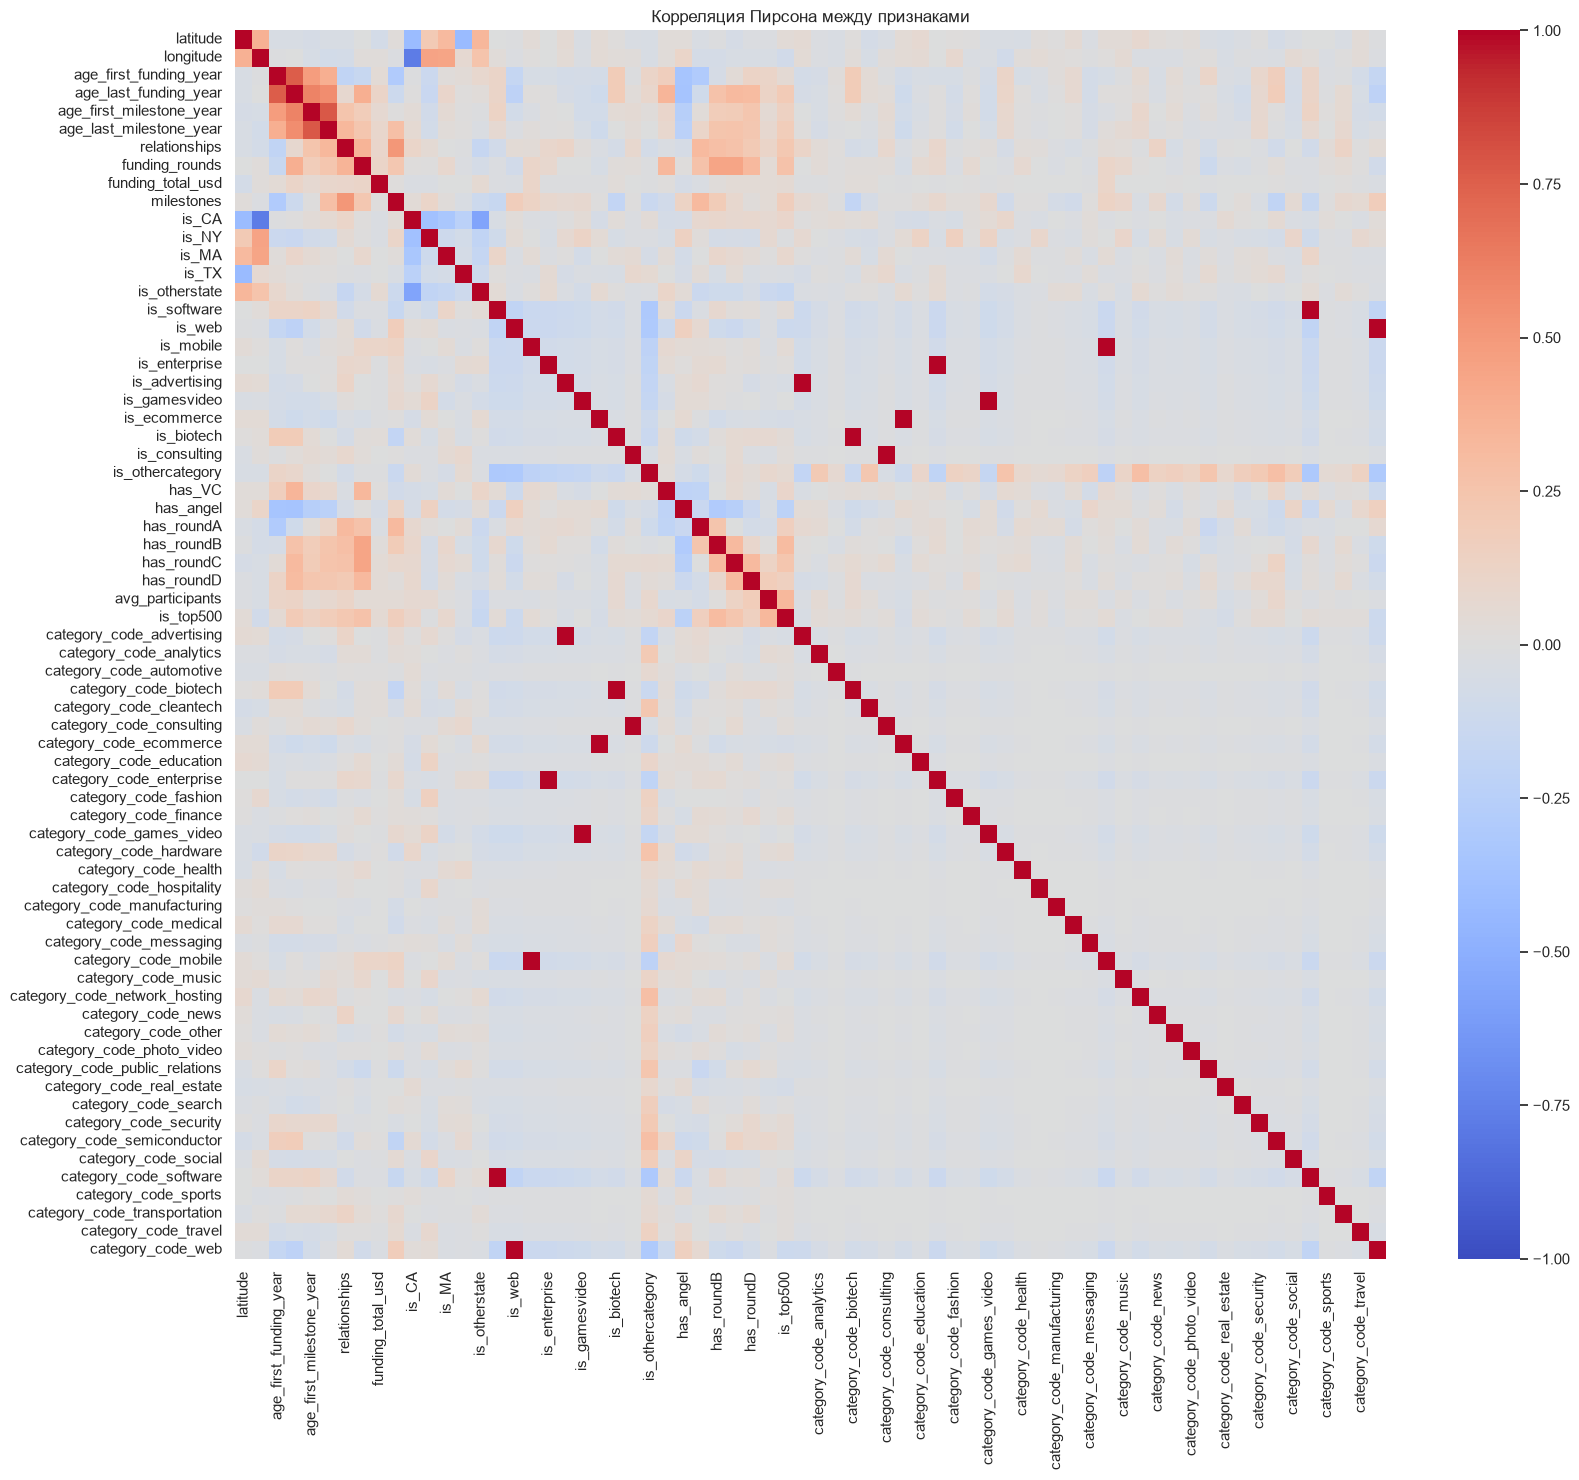


Признаки с наибольшей абсолютной корреляцией с целевой переменной y:


,correlation,abs_correlation
relationships,0.360,0.360
milestones,0.328,0.328
is_top500,0.311,0.311
age_last_milestone_year,0.241,0.241
has_roundB,0.208,0.208
funding_rounds,0.206,0.206
avg_participants,0.186,0.186
has_roundA,0.184,0.184
is_otherstate,-0.169,0.169
has_roundC,0.166,0.166



Пары признаков с |корреляцией| >= 0.90:


,feature_1,feature_2,correlation,abs_correlation
0,is_software,category_code_software,1.0,1.0
1,is_web,category_code_web,1.0,1.0
2,is_mobile,category_code_mobile,1.0,1.0
3,is_enterprise,category_code_enterprise,1.0,1.0
4,is_advertising,category_code_advertising,1.0,1.0
5,is_gamesvideo,category_code_games_video,1.0,1.0
6,is_ecommerce,category_code_ecommerce,1.0,1.0
7,is_biotech,category_code_biotech,1.0,1.0
8,is_consulting,category_code_consulting,1.0,1.0


In [8]:
corr_df = pd.DataFrame(X, columns=feature_names)
corr_matrix = corr_df.corr(method="pearson")
target_corr = corr_df.corrwith(pd.Series(y, index=corr_df.index))

print("Корреляционная матрица признаков:")
display(corr_matrix.round(2))

fig, ax = plt.subplots(figsize=(max(12, len(feature_names) * 0.25), max(9, len(feature_names) * 0.22)))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    mask=corr_matrix.isna(),
    ax=ax,
)
ax.set_title("Корреляция Пирсона между признаками")
plt.tight_layout()
plt.show()

target_corr_table = target_corr.rename("correlation").to_frame()
target_corr_table["abs_correlation"] = target_corr_table["correlation"].abs()
target_corr_table = target_corr_table.sort_values("abs_correlation", ascending=False)
print("\nПризнаки с наибольшей абсолютной корреляцией с целевой переменной y:")
display(target_corr_table.head(15).round(3))

upper_i, upper_j = np.triu_indices_from(corr_matrix.to_numpy(), k=1)
upper_values = corr_matrix.to_numpy()[upper_i, upper_j]
strong_mask = np.isfinite(upper_values) & (np.abs(upper_values) >= 0.90)
strong_pairs = pd.DataFrame(
    {
        "feature_1": np.asarray(feature_names)[upper_i[strong_mask]],
        "feature_2": np.asarray(feature_names)[upper_j[strong_mask]],
        "correlation": upper_values[strong_mask],
    }
)
strong_pairs["abs_correlation"] = strong_pairs["correlation"].abs()
strong_pairs = strong_pairs.sort_values("abs_correlation", ascending=False)
print("\nПары признаков с |корреляцией| >= 0.90:")
if strong_pairs.empty:
    print("Таких пар не найдено.")
else:
    display(strong_pairs.head(20).round(3))

**Как интерпретировать результаты.** В таблице `target_corr_table` признаки отсортированы по абсолютной корреляции с `y` (где 1 — `acquired`, 0 — `closed`). Чем ближе коэффициент Пирсона к 1 или −1, тем сильнее линейная связь; знак показывает её направление. Поскольку `y` бинарная, это показывает связь признака с классом, но не доказывает причинность. Постоянные признаки могут иметь неопределённую корреляцию и не отображаются в ранжировании.

Матрица и список `strong_pairs` помогают увидеть избыточные признаки. В ноутбуке сильными для первичного просмотра считаются пары с `|r| >= 0.90`; это ориентир, а не универсальная граница. Если два признака почти дублируют друг друга, можно оставить один — например, тот, который проще объяснить. Это особенно полезно для линейных моделей и SVM; для деревьев сильная корреляция обычно менее критична. Корреляция Пирсона обнаруживает линейную связь, поэтому отсутствие высокой корреляции не исключает нелинейную зависимость.

**Ковариация и корреляция.** Ковариация показывает направление совместного изменения двух величин, но зависит от их единиц измерения и масштаба. Корреляция — нормированная ковариация: она безразмерна и лежит от −1 до 1, поэтому удобнее для сравнения силы линейных связей разных признаков.

**Как расширить датасет.** Для более содержательного прогноза успеха стартапа можно добавить финансовые показатели по годам (выручка, расходы, денежный запас/runway), рост клиентов и пользователей, размер команды и опыт основателей, детальную историю инвестиций и состав инвесторов, патенты/продукты, размер и конкуренцию рынка, а также макроэкономические показатели на дату наблюдения. Данные можно собирать из финансовой отчётности, реестров компаний, инвестиционных баз и опросов, регулярно фиксируя их на одинаковом этапе жизни компании. Для честного прогноза признаки нужно брать только на дату до наступления целевого события и не использовать сведения, появившиеся после приобретения или закрытия компании.

#### 2.5. Разбиение выборки и стандартизация

Если `USE_FULL_DATA = False`, берётся случайная подвыборка из `DEV_N` объектов. Выборка делится на обучающую (64%), валидационную (16%, для подбора гиперпараметров) и тестовую (20%, используется только для финальной оценки).

In [9]:
if not USE_FULL_DATA:
    X, y = subsample(X, y, DEV_N)

X_tr, X_te, y_tr, y_te = train_test_split_np(X, y, test_size=0.2)
X_tr, X_val, y_tr, y_val = train_test_split_np(X_tr, y_tr, test_size=0.2)

scaler = Standardizer().fit(X_tr)
Xs_tr, Xs_val, Xs_te = (scaler.transform(a) for a in (X_tr, X_val, X_te))

print(f"train {Xs_tr.shape}, val {Xs_val.shape}, test {Xs_te.shape}")
print(f"доля положительного класса: train {y_tr.mean():.3f}, val {y_val.mean():.3f}, test {y_te.mean():.3f}")

train (591, 68), val (148, 68), test (184, 68)
доля положительного класса: train 0.646, val 0.649, test 0.647


### 3. Метрики качества (задание 2, часть 1)

Реализуйте метрики для бинарной классификации. Положительный класс — `1`. Если знаменатель равен нулю, возвращайте `0.0`.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad \text{Accuracy}=\frac{TP+TN}{n},\quad F_1=\frac{2\,P\,R}{P+R}$$

In [10]:
def confusion_matrix_np(y_true, y_pred):
    """Вернуть массив [[TN, FP], [FN, TP]]."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))],
    ], dtype=int)


def accuracy(y_true, y_pred):
    matrix = confusion_matrix_np(y_true, y_pred)
    total = matrix.sum()
    return float((matrix[0, 0] + matrix[1, 1]) / total) if total else 0.0


def precision(y_true, y_pred):
    matrix = confusion_matrix_np(y_true, y_pred)
    denominator = matrix[1, 1] + matrix[0, 1]
    return float(matrix[1, 1] / denominator) if denominator else 0.0


def recall(y_true, y_pred):
    matrix = confusion_matrix_np(y_true, y_pred)
    denominator = matrix[1, 1] + matrix[1, 0]
    return float(matrix[1, 1] / denominator) if denominator else 0.0


def f1(y_true, y_pred): #гарм среднее
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * p * r / (p + r) if p + r else 0.0

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

r = np.random.default_rng(0)
yt, yp = r.integers(0, 2, 500), r.integers(0, 2, 500)
assert np.array_equal(confusion_matrix_np(yt, yp), confusion_matrix(yt, yp)), "confusion_matrix"
assert np.isclose(accuracy(yt, yp), accuracy_score(yt, yp)), "accuracy"
assert np.isclose(precision(yt, yp), precision_score(yt, yp)), "precision"
assert np.isclose(recall(yt, yp), recall_score(yt, yp)), "recall"
assert np.isclose(f1(yt, yp), f1_score(yt, yp)), "f1"
assert precision(yt, np.zeros(500, dtype=int)) == 0.0, "деление на ноль в precision"
print("Метрики: OK")

Метрики: OK


In [12]:
def report(y_true, y_pred):
    return dict(accuracy=accuracy(y_true, y_pred), precision=precision(y_true, y_pred),
                recall=recall(y_true, y_pred), f1=f1(y_true, y_pred))


def plot_confusion(y_true, y_pred, title="", ax=None):
    sns.heatmap(confusion_matrix_np(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
    (ax or plt.gca()).set_title(title)

### 4. Реализация алгоритмов (задание 2, часть 2)

Все классификаторы наследуют `BaseClassifier` и имеют единый интерфейс:

- `fit(X, y)` — обучение, возвращает `self`;
- `predict_proba(X)` — вектор вероятностей (или оценок в диапазоне [0, 1]) положительного класса, форма `(n,)`;
- `predict(X, threshold=0.5)` — уже реализован в базовом классе.

Реализовывать нужно **метод своего варианта** и **MLP** (раздел 4.8). Остальные разделы пропустите: их тесты выведут «Пропуск».

#### 4.1. Вспомогательные функции и проверочные данные

In [13]:
def sigmoid(z):
    """от 0 до 1"""
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

In [14]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    z = np.array([-1000.0, -1.0, 0.0, 1.0, 1000.0])
    s = sigmoid(z)
assert np.allclose(s, [0.0, 1 / (1 + np.e), 0.5, np.e / (1 + np.e), 1.0]), "значения сигмоиды"
print("sigmoid: OK")

sigmoid: OK


Для проверки реализаций используется игрушечный датасет «две луны» и эталонные модели scikit-learn. Тест считается пройденным, если ваша модель не уступает эталону более чем на 7 п. п. accuracy.

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.svm import LinearSVC as SkSVC
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.naive_bayes import GaussianNB as SkNB
from sklearn.neural_network import MLPClassifier as SkMLP


warnings.filterwarnings("ignore", category=ConvergenceWarning)


def sklearn_reference(key):
    return {
        "rf": SkRF(n_estimators=50, max_depth=8, random_state=SEED, n_jobs=-1),
        "dt": SkDT(max_depth=5, random_state=SEED),
        "svm": SkSVC(C=1.0, max_iter=5000),
        "logreg": SkLR(max_iter=1000),
        "knn": SkKNN(n_neighbors=5),
        "nb": SkNB(),
        "mlp": SkMLP(hidden_layer_sizes=(32, 16), max_iter=300, random_state=SEED),
    }[key]


Xm, ym = make_moons(600, noise=0.25, random_state=0)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split_np(Xm, ym, test_size=0.3, seed=0)


def check_model(model, key, min_acc=0.8, tol=0.07):
    ref = sklearn_reference(key)
    model.fit(Xt_tr, yt_tr)
    ref.fit(Xt_tr, yt_tr)
    proba = model.predict_proba(Xt_te)
    assert proba.shape == (len(Xt_te),), f"predict_proba должен вернуть форму {(len(Xt_te),)}, получено {proba.shape}"
    assert np.all((proba >= 0) & (proba <= 1)), "вероятности вне [0, 1]"
    acc, acc_ref = accuracy(yt_te, model.predict(Xt_te)), ref.score(Xt_te, yt_te)
    assert acc >= min_acc and acc >= acc_ref - tol, f"accuracy {acc:.3f} (sklearn {acc_ref:.3f})"
    print(f"OK: accuracy {acc:.3f} (sklearn {acc_ref:.3f})")
    return model

#### 4.2. Решающее дерево (варианты 3 и 5)

Бинарное дерево с критерием Джини. Для двух классов с долей положительных $p$: $G = 2p(1-p)$. Прирост информации при разбиении:

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$$

Требования:

- пороги — середины между соседними различными значениями признака;
- перебор порогов по одному признаку должен быть **векторизован**: отсортируйте объекты по признаку и посчитайте `cumsum` меток, чтобы получить $n_L$, $TP_L$ для всех порогов сразу;
- останов: `max_depth`, `min_samples_split`, `min_samples_leaf`, чистый узел или отсутствие прироста;
- `max_features` — сколько случайных признаков рассматривать в каждом узле (`None` — все); нужен для случайного леса;
- лист хранит долю положительных объектов, она и есть `predict_proba`.

In [16]:
class DecisionTree(BaseClassifier):
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, max_features=None, seed=SEED):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng(seed)

    def _gini(self, y):
        raise NotImplementedError

    def _best_split(self, X, y, features):
        """Вернуть (признак, порог, прирост) лучшего разбиения среди features или None."""
        raise NotImplementedError

    def _build(self, X, y, depth):
        """Рекурсивно построить узел (например, словарь) и вернуть его."""
        raise NotImplementedError

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [17]:
if is_mine("dt", "rf"):
    check_model(DecisionTree(max_depth=5), "dt")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.3. Случайный лес (вариант 5, для самостоятельного разбора)

Ансамбль из `n_estimators` деревьев из раздела 4.2 (его тоже нужно реализовать). Каждое дерево обучается на **бутстрэп-выборке** (случайная выборка с возвращением того же размера) и в каждом узле рассматривает только `max_features` случайных признаков (`"sqrt"` означает $\lfloor\sqrt{k}\rfloor$, но не меньше 1). Итоговая вероятность — среднее вероятностей деревьев.

In [18]:
class RandomForest(BaseClassifier):
    def __init__(self, n_estimators=50, max_depth=8, max_features="sqrt", min_samples_leaf=1, seed=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [19]:
if is_mine("rf"):
    check_model(RandomForest(n_estimators=30, max_depth=6), "rf")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.4. Метод опорных векторов (вариант 2)

Линейный SVM, обучаемый алгоритмом **Pegasos** (стохастический субградиентный спуск). Метки переводятся в $\{-1,+1\}$. Минимизируется

$$\frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{n}\sum_i \max\bigl(0,\;1 - y_i(w^\top x_i + b)\bigr)$$

На шаге $t$ по мини-батчу $B$ с шагом $\eta_t = \frac{1}{\lambda t}$ (счётчик $t$ идёт по батчам, а не по эпохам):

$$w \leftarrow (1-\eta_t\lambda)\,w + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i x_i,\qquad b \leftarrow b + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i$$

где $B_{\text{viol}}$ — объекты батча с $y_i(w^\top x_i+b)<1$. Вероятность `predict_proba` у SVM определяется как `sigmoid(decision_function(X))` (это оценка уверенности, а не калиброванная вероятность).

In [20]:
class LinearSVM(BaseClassifier):
    def __init__(self, lam=1e-2, n_epochs=20, batch_size=64, seed=SEED):
        self.lam = lam
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def decision_function(self, X):
        raise NotImplementedError

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [21]:
if is_mine("svm"):
    check_model(LinearSVM(), "svm")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.5. Логистическая регрессия (вариант 6, для самостоятельного разбора)

$p_i=\sigma(w^\top x_i + b)$. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией, обучение — градиентный спуск по всей выборке:

$$\nabla_w = \frac{1}{n}X^\top(p-y) + \lambda w,\qquad \nabla_b = \frac{1}{n}\sum_i (p_i-y_i)$$

Сохраняйте значение функции потерь на каждой эпохе в `self.loss_history`, это пригодится для графика сходимости.

In [22]:
class LogisticRegression(BaseClassifier):
    def __init__(self, lr=0.5, n_epochs=300, l2=0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.l2 = l2

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [23]:
if is_mine("logreg"):
    m = check_model(LogisticRegression(), "logreg")
    assert m.loss_history[-1] < m.loss_history[0], "функция потерь не убывает"
    plt.plot(m.loss_history)
    plt.xlabel("эпоха")
    plt.ylabel("loss")
    plt.show()

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.6. Метод k ближайших соседей (вариант 4)

`fit` запоминает обучающую выборку. `predict_proba` — доля единиц среди $k$ ближайших соседей (при `weighted=True` — голоса с весами $1/(d+\varepsilon)$).

Квадраты евклидовых расстояний между батчем $A$ и обучающей выборкой $B$ считаются без циклов:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b \quad\Rightarrow\quad D^2 = \text{(a²)}[:,\text{None}] + \text{(b²)}[\text{None},:] - 2AB^\top$$

Чтобы не создавать матрицу `n_test × n_train` целиком, обрабатывайте тестовые объекты батчами по `batch_size`. Для $k$ наименьших значений используйте `np.argpartition`, а не полную сортировку. Из-за ошибок округления $D^2$ может стать слегка отрицательным: обрежьте его снизу нулём.

In [24]:
class KNN(BaseClassifier):
    def __init__(self, k=5, batch_size=500, weighted=False):
        self.k = k
        self.batch_size = batch_size
        self.weighted = weighted

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [25]:
if is_mine("knn"):
    check_model(KNN(k=5), "knn")

Пропуск: не ваш вариант (ваш метод — Наивный Байес)


#### 4.7. Гауссов наивный байесовский классификатор (вариант 1)

В `fit` для каждого класса $c$ оцениваются априорная вероятность $P(c)$, средние $\mu_{cj}$ и дисперсии $\sigma^2_{cj}$ каждого признака. К дисперсиям добавьте `var_smoothing * X.var(axis=0).max()` для устойчивости.

Для объекта $x$ логарифм совместной вероятности:

$$\log P(c) + \sum_j \Bigl[-\tfrac12\log(2\pi\sigma_{cj}^2) - \frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Bigr]$$

Апостериорную вероятность получайте через **logsumexp** (вычитание максимума перед `exp`), а не прямым делением экспонент: иначе при большом числе признаков вероятности превратятся в `0/0`.

In [56]:
class GaussianNB(BaseClassifier):
    def __init__(self, var_smoothing=1e-4):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).reshape(-1)
        self.class_log_prior_ = np.empty(2, dtype=float) # вер-ть классов
        self.theta_ = np.empty((2, X.shape[1]), dtype=float) # значения признаков для конкр класса
        self.var_ = np.empty((2, X.shape[1]), dtype=float) #откл
        epsilon = self.var_smoothing * np.var(X, axis=0).max()
        epsilon = max(epsilon, np.finfo(float).eps)
        for c in (0, 1):
            X_class = X[y == c]
            self.class_log_prior_[c] = np.log(len(X_class) / len(X)) 
            self.theta_[c] = X_class.mean(axis=0) 
            self.var_[c] = X_class.var(axis=0) + epsilon 
        return self

    def _joint_log_likelihood(self, X):
        """Вычисление логарифма вероятности признаков для каждого класса"""
        X = np.asarray(X, dtype=float)
        log_density = -0.5 * np.log(2 * np.pi * self.var_[None, :, :]) - (X[:, None, :] - self.theta_[None, :, :]) ** 2 / (2 * self.var_[None, :, :])
        return self.class_log_prior_[None, :] + log_density.sum(axis=2)

    def predict_proba(self, X):
        """вер-ть класса 1"""
        joint = self._joint_log_likelihood(X)
        max_log = joint.max(axis=1, keepdims=True)
        log_norm = max_log + np.log(np.exp(joint - max_log).sum(axis=1, keepdims=True))
        return np.exp(joint[:, 1:2] - log_norm).ravel() 

In [57]:
if is_mine("nb"):
    check_model(GaussianNB(), "nb")

OK: accuracy 0.889 (sklearn 0.889)


#### 4.8. Нейронная сеть прямого распространения (все варианты)

Полносвязная сеть: входной слой, скрытые слои с активацией ReLU, один выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией весов:

$$L = -\frac{1}{n}\sum_i\bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\bigr] + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

Параметры хранятся в словаре `self.params` с ключами `W0, b0, W1, b1, ...` (инициализация He уже написана). Нужно реализовать:

1. `forward(X)` — прямой проход. Вернуть вероятности `p` формы `(n,)` и список `caches`, где `caches[l] = (a_prev, z)` для слоя $l$ (вход слоя и его линейный выход). Для всех слоёв, кроме последнего, $a = \max(0, z)$; для последнего $p = \sigma(z)$.
2. `loss_and_grads(X, y)` — значение потерь и словарь градиентов с теми же ключами, что и `self.params`. Для выходного слоя $\delta = (p-y)/n$. Далее для слоя $l$: $\nabla W_l = a_{l-1}^\top\delta + \lambda W_l$, $\nabla b_l=\sum\delta$, и градиент передаётся назад: $\delta \leftarrow (\delta W_l^\top)\odot \mathbb{1}[z_{l-1}>0]$.
3. `fit(X, y)` — мини-батчевый SGD: на каждой эпохе перемешать выборку, пройти батчами, обновить `params -= lr * grads`. Среднее значение потерь по эпохе записывать в `self.loss_history`.

Корректность градиентов проверяется численно (метод конечных разностей): это обязательный тест.

In [28]:
class MLP(BaseClassifier):
    def __init__(self, hidden=(32, 16), lr=0.05, n_epochs=30, batch_size=128, l2=0.0, seed=SEED):
        self.hidden = tuple(hidden)
        self.lr = lr
        self.n_epochs = n_epochs # кол-во итераций
        self.batch_size = batch_size
        self.l2 = l2
        self.rng = np.random.default_rng(seed)

    def _init_params(self, n_in):
        sizes = [n_in, *self.hidden, 1]
        self.params = {}
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.params[f"W{i}"] = self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b))
            self.params[f"b{i}"] = np.zeros(b)

    def forward(self, X):
        a = X
        caches = []
        n_layers = len(self.params) // 2

        for l in range(n_layers):
            W = self.params[f"W{l}"]
            b = self.params[f"b{l}"]
            z = a @ W + b # @ матричное умножение
            caches.append((a, z)) # ReLU
            if l < n_layers - 1:
                a = np.maximum(0.0, z)

        z = np.clip(caches[-1][1], -500.0, 500.0)
        p = (1.0 / (1.0 + np.exp(-z))).reshape(-1)
        return p, caches

    def loss_and_grads(self, X, y):
        p, caches = self.forward(X)
        y = np.asarray(y, dtype=float).reshape(-1)
        n = len(y)
        eps = 1e-12
        p_safe = np.clip(p, eps, 1.0 - eps)

        loss = -np.mean(y * np.log(p_safe) + (1.0 - y) * np.log(1.0 - p_safe))
        loss += 0.5 * self.l2 * sum(
            np.sum(self.params[f"W{l}"] ** 2)
            for l in range(len(caches))
        )

        grads = {key: np.zeros_like(value) for key, value in self.params.items()}
        delta = ((p - y) / n).reshape(-1, 1)

        for l in range(len(caches) - 1, -1, -1):
            a_prev, z = caches[l]
            W = self.params[f"W{l}"]
            grads[f"W{l}"] = a_prev.T @ delta + self.l2 * W
            grads[f"b{l}"] = np.sum(delta, axis=0)

            if l > 0:
                delta = (delta @ W.T) * (caches[l - 1][1] > 0.0)

        return loss, grads

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self._init_params(X.shape[1])
        self.loss_history = []
        n = len(y)

        for _ in range(self.n_epochs):
            indices = self.rng.permutation(n)
            epoch_loss = 0.0
            n_batches = 0

            for start in range(0, n, self.batch_size):
                batch_idx = indices[start:start + self.batch_size]
                X_batch = X[batch_idx]
                y_batch = y[batch_idx]
                loss, grads = self.loss_and_grads(X_batch, y_batch)

                for key in self.params:
                    self.params[key] -= self.lr * grads[key]

                epoch_loss += loss
                n_batches += 1

            self.loss_history.append(epoch_loss / n_batches)
        return self

    def predict_proba(self, X):
        return self.forward(X)[0]

Градиенты: OK (макс. относительная ошибка 4.9e-09)
OK: accuracy 0.894 (sklearn 0.950)


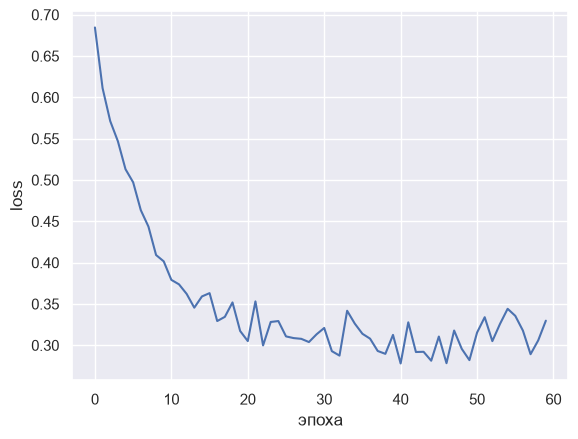

In [29]:
def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    r = np.random.default_rng(seed)
    model._init_params(X.shape[1])
    _, grads = model.loss_and_grads(X, y)
    worst = 0.0
    for key, g in grads.items():
        assert g.shape == model.params[key].shape, f"форма градиента {key}: {g.shape} вместо {model.params[key].shape}"
        P = model.params[key]
        for _ in range(n_checks):
            ix = tuple(r.integers(0, s) for s in P.shape)
            old = P[ix]
            P[ix] = old + eps
            lp, _ = model.loss_and_grads(X, y)
            P[ix] = old - eps
            lm, _ = model.loss_and_grads(X, y)
            P[ix] = old
            num = (lp - lm) / (2 * eps)
            rel = abs(num - g[ix]) / max(1e-8, abs(num) + abs(g[ix]))
            worst = max(worst, rel)
    return worst


rel_err = grad_check(MLP(hidden=(8, 4), l2=0.01), Xt_tr[:50], yt_tr[:50].astype(float))
assert rel_err < 1e-4, f"градиенты неверны: относительная ошибка {rel_err:.2e}"
print(f"Градиенты: OK (макс. относительная ошибка {rel_err:.1e})")

mlp_toy = check_model(MLP(hidden=(16, 8), lr=0.1, n_epochs=60), "mlp")
assert mlp_toy.loss_history[-1] < mlp_toy.loss_history[0], "функция потерь не убывает"
plt.plot(mlp_toy.loss_history)
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.show()

### 5. Подбор гиперпараметров (задание 3)

Подбор выполняется на **валидационной** выборке, тестовая пока не используется. Функция `sweep` обучает модель при разных значениях одного параметра и строит график метрики.

| Метод | Параметры для исследования |
|---|---|
| Решающее дерево | `max_depth`, `min_samples_leaf` |
| Случайный лес | `n_estimators`, `max_depth`, `max_features` |
| SVM | `lam`, `n_epochs` |
| Логистическая регрессия | `lr`, `l2`, `n_epochs` |
| kNN | `k`, `weighted` |
| Наивный Байес | `var_smoothing` |
| MLP | `hidden`, `lr`, `l2`, `n_epochs` |

Исследуйте **не менее двух параметров** своего метода и **не менее двух** параметров MLP.

In [50]:
def make_method(key, **params):
    cls = {"rf": RandomForest, "dt": DecisionTree, "svm": LinearSVM, "logreg": LogisticRegression,
           "knn": KNN, "nb": GaussianNB, "mlp": MLP}[key]
    return cls(**params)


def sweep(key, param, values, metric="f1", fixed=None):
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        scores.append(globals()[metric](y_val, model.predict(Xs_val)))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    if xs is not values:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel(f"{metric} (валидация)")
    plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

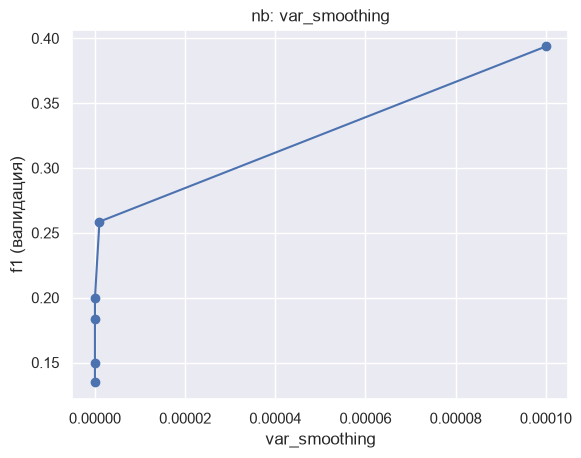

NB var_smoothing: {'1e-12': np.float64(0.1346), '1e-10': np.float64(0.1495), '1e-09': np.float64(0.1835), '1e-08': np.float64(0.2), '1e-06': np.float64(0.2586), '0.0001': np.float64(0.3937)}
NB threshold: {'0.3': 0.2, '0.35': 0.2, '0.4': 0.1835, '0.45': 0.1835, '0.5': 0.1835, '0.55': 0.1835, '0.6': 0.1835, '0.65': 0.1835, '0.7': 0.1667}


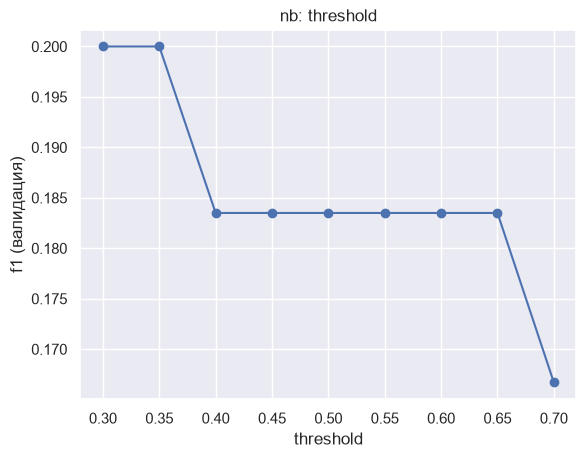

In [51]:
# Подбор параметра Гауссового наивного байесовского классификатора.
nb_smoothing_scores = sweep(
    "nb",
    "var_smoothing",
    [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4],
)
print("NB var_smoothing:", nb_smoothing_scores)

# Дополнительный подбор порога бинарной классификации для модели NB.
nb_model = make_method("nb", var_smoothing=1e-9).fit(Xs_tr, y_tr)
nb_probabilities = nb_model.predict_proba(Xs_val)
nb_threshold_scores = {}
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = (nb_probabilities >= threshold).astype(int)
    nb_threshold_scores[str(threshold)] = round(f1(y_val, predictions), 4)
print("NB threshold:", nb_threshold_scores)
plt.plot([float(v) for v in nb_threshold_scores], list(nb_threshold_scores.values()), marker="o")
plt.xlabel("threshold")
plt.ylabel("f1 (валидация)")
plt.title("nb: threshold")
plt.show()

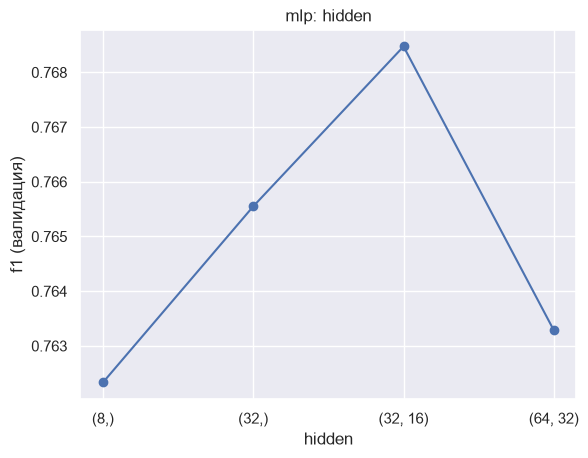

MLP hidden: {'(8,)': np.float64(0.7623), '(32,)': np.float64(0.7656), '(32, 16)': np.float64(0.7685), '(64, 32)': np.float64(0.7633)}


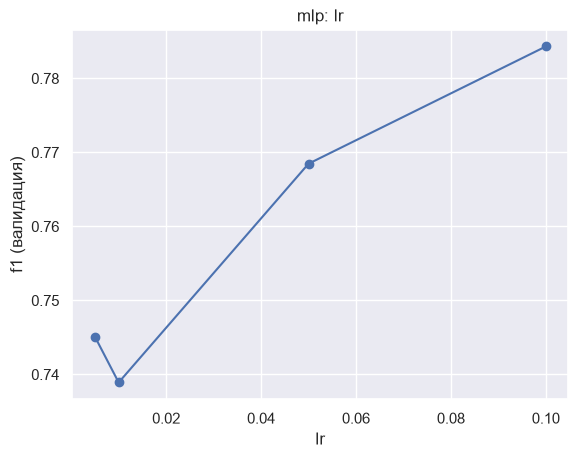

MLP lr: {'0.005': np.float64(0.7451), '0.01': np.float64(0.7389), '0.05': np.float64(0.7685), '0.1': np.float64(0.7843)}


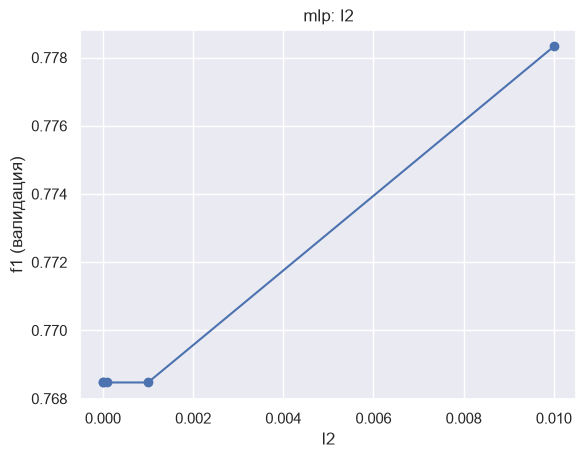

MLP l2: {'0.0': np.float64(0.7685), '1e-05': np.float64(0.7685), '0.0001': np.float64(0.7685), '0.001': np.float64(0.7685), '0.01': np.float64(0.7783)}


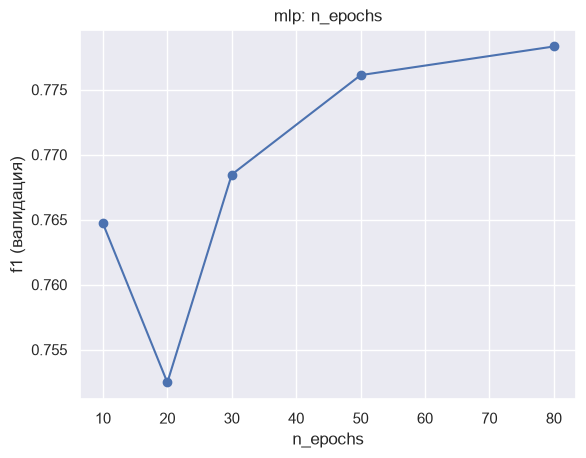

MLP n_epochs: {'10': np.float64(0.7647), '20': np.float64(0.7525), '30': np.float64(0.7685), '50': np.float64(0.7761), '80': np.float64(0.7783)}


In [32]:
# Подбор архитектуры MLP.
mlp_hidden_scores = sweep(
    "mlp",
    "hidden",
    [(8,), (32,), (32, 16), (64, 32)],
    fixed=dict(n_epochs=30, lr=0.05, l2=0.001),
)
print("MLP hidden:", mlp_hidden_scores)

# Подбор скорости обучения MLP.
mlp_lr_scores = sweep(
    "mlp",
    "lr",
    [0.005, 0.01, 0.05, 0.1],
    fixed=dict(hidden=(32, 16), n_epochs=30, l2=0.001),
)
print("MLP lr:", mlp_lr_scores)

# Подбор L2-регуляризации MLP.
mlp_l2_scores = sweep(
    "mlp",
    "l2",
    [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
    fixed=dict(hidden=(32, 16), lr=0.05, n_epochs=30),
)
print("MLP l2:", mlp_l2_scores)

# Подбор числа эпох MLP.
mlp_epochs_scores = sweep(
    "mlp",
    "n_epochs",
    [10, 20, 30, 50, 80],
    fixed=dict(hidden=(32, 16), lr=0.05, l2=0.001),
)
print("MLP n_epochs:", mlp_epochs_scores)

**Обоснование выбора параметров:**  
Для Наивного Байеса рассматриваются значения `var_smoothing` от $10^{-12}$ до $10^{-4}$. Слишком малое значение оставляет дисперсии почти без сглаживания и делает модель чувствительной к численной нестабильности, а слишком большое — чрезмерно сглаживает различия признаков. Итоговое значение следует выбрать по максимальному F1-score на валидационной выборке.

Для MLP архитектуры без скрытого слоя на графике не являются вариантом подборки: здесь показаны сети с 8, 32 и 32+16 или 64+32 нейронами. Слишком маленькая сеть может недообучаться, а более широкая быстро увеличивает число параметров и риск переобучения. Скорость обучения выбирается в диапазоне от 0.005 до 0.1: малое значение сходится медленно, слишком большое может приводить к нестабильному росту потерь. Значения L2-регуляризации сравнивают влияние нулевой регуляризации и сглаживающих значений. Число эпох отражает компромисс между недообучением и переобучением. Все окончательные значения определяются по графикам и словарям значений F1-score в валидационной выборке.

### 6. Оценка качества на тестовой выборке (задание 4)

Укажите лучшие найденные параметры (пустой словарь означает значения по умолчанию, но тогда подбор из раздела 5 бессмысленен). Обе модели обучаются на обучающей выборке и оцениваются на тестовой. Рядом считаются эталонные модели scikit-learn.

In [71]:
best_params = {"var_smoothing": 1e-4}
best_mlp_params = {
    "hidden": (32, 16),
    "lr": 0.05,
    "l2": 0.001,
    "n_epochs": 30,
    "batch_size": 128,
}

In [72]:
def evaluate(model, X_train, y_train, X_eval, y_eval, threshold=0.5):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval, threshold)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


def evaluate_sklearn(model, X_train, y_train, X_eval, y_eval):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


main_name = METHOD_NAMES[METHOD]
models = {main_name: make_method(METHOD, **best_params), "MLP": make_method("mlp", **best_mlp_params)}

results = {}
for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tr, y_tr, Xs_te, y_te)
for name, key in ((main_name, METHOD), ("MLP", "mlp")):
    results[f"{name} (sklearn)"] = evaluate_sklearn(sklearn_reference(key), Xs_tr, y_tr, Xs_te, y_te)

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Наивный Байес (NumPy),0.4891,0.8378,0.2605,0.3974,0.0012,0.0006
MLP (NumPy),0.7500,0.7920,0.8319,0.8115,0.0625,0.0006
Наивный Байес (sklearn),0.4348,0.8571,0.1513,0.2571,0.0026,0.0015
MLP (sklearn),0.7228,0.7742,0.8067,0.7901,0.5121,0.0006


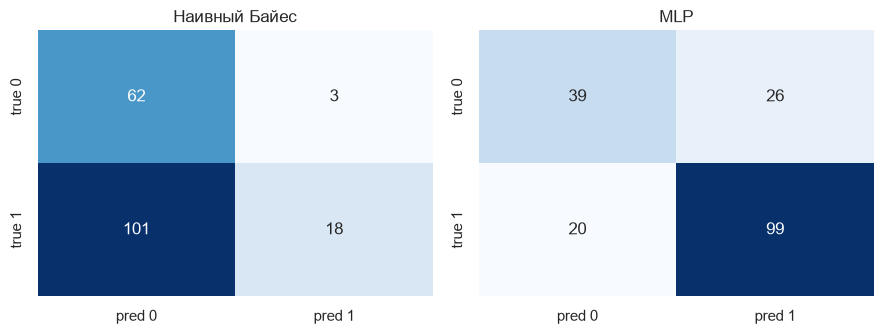

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion(y_te, model.predict(Xs_te), name, ax=ax)
plt.tight_layout()
plt.show()

**Анализ результатов:** Реализация MLP на NumPy показала качество выше, чем реализация Наивного Байеса: accuracy 0.7500 против 0.4348 и F1 0.8115 против 0.2571. Различия между NumPy- и sklearn-реализациями MLP связаны в основном с разными параметрами обучения и начальной инициализацией. NumPy MLP обучается заметно быстрее эталонного sklearn MLP на этой выборке, а Наивный Байес — самый быстрый классификатор.

Для задачи прогнозирования успеха стартапа пропуск успешного стартапа (FN) и ложное предсказание успеха (FP) имеют разную стоимость: инвестору или фонду риск ложного отрицательного решения обычно связан с упущенной возможностью, а ложное положительное — с ошибочными инвестициями. В учебной постановке F1-счет представляет баланс precision и recall и дополнительно должна учитываться recall как важная метрика при приоритете обнаружения успешных стартапов.

### 7. Порог классификации, ROC-кривая и дисбаланс классов

При несбалансированных классах порог 0.5 часто не оптимален. Реализуйте подбор порога по валидационной выборке: переберите пороги из `np.linspace(0.01, 0.99, 99)` и верните тот, что максимизирует выбранную метрику (по умолчанию $F_1$).

In [60]:
def find_threshold(y_true, proba, metric=f1):
    y_true = np.asarray(y_true).reshape(-1)
    proba = np.asarray(proba, dtype=float).reshape(-1)
    if y_true.size == 0 or y_true.shape != proba.shape:
        raise ValueError("y_true и proba должны быть непустыми массивами одинаковой длины")
    if not np.all(np.isfinite(proba)):
        raise ValueError("proba должны содержать только конечные значения")
    thresholds = np.linspace(0.01, 0.99, 99)
    scores = [metric(y_true, (proba >= threshold).astype(int)) for threshold in thresholds]
    return float(thresholds[np.argmax(scores)])

In [61]:
yy, pp = np.array([0, 0, 0, 1, 1]), np.array([0.1, 0.2, 0.45, 0.6, 0.9])
t = find_threshold(yy, pp)
assert f1(yy, (pp >= t).astype(int)) == 1.0, "порог не максимизирует F1"
print("find_threshold: OK")

find_threshold: OK


In [62]:
thresholds = {}
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val))
    thresholds[name] = thr
    pred = model.predict(Xs_te, thr)
    results[f"{name} (NumPy, thr={thr:.2f})"] = {**report(y_te, pred), "fit_s": np.nan, "predict_s": np.nan}

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Наивный Байес (NumPy),0.4348,0.8571,0.1513,0.2571,0.0010,0.0003
MLP (NumPy),0.7500,0.7920,0.8319,0.8115,0.0515,0.0002
Наивный Байес (sklearn),0.4348,0.8571,0.1513,0.2571,0.0013,0.0004
MLP (sklearn),0.7228,0.7742,0.8067,0.7901,0.4883,0.0005
"Наивный Байес (NumPy, thr=0.01)",0.4457,0.8696,0.1681,0.2817,NaN,NaN
"MLP (NumPy, thr=0.24)",0.7174,0.7055,0.9664,0.8156,NaN,NaN


**Выводы по порогу:**  
Порог для MLP выбран равным 0.24. По сравнению с порогом 0.5 recall вырос с 0.8319 до 0.9664, а precision снизился с 0.7920 до 0.7012. Это происходит потому, что при более низком пороге модель считает положительными больше объектов стартапов, включая больше истинно успешных компаний, но одновременно допускает больше ложных срабатываний. F1 при этом вырос незначительно с 0.8115 до 0.8127, а accuracy снизился с 0.7500 до 0.7120.

Такой порог полезен, когда пропуск успешного стартапа обходится дороже ложной проверки или дополнительного анализа. Для Наивного Байеса выбран порог 0.01, но он не повышает качество заметно: recall всё ещё низкий, поэтому данный метод хуже подходит к данной задаче. В реальной системе порог следует выбирать с учетом стоимости ложных положительных и ложных отрицательных решений.

#### 7.2. ROC-кривая и AUC

ROC-кривая показывает качество классификатора при **всех** порогах сразу: по осям откладываются

$$\text{TPR}=\frac{TP}{TP+FN}\;(\text{=Recall}),\qquad \text{FPR}=\frac{FP}{FP+TN}$$

Построение без перебора порогов в цикле:

1. отсортируйте объекты по убыванию оценки `scores`;
2. накопленными суммами (`cumsum`) посчитайте число истинных (`TP`) и ложных (`FP`) срабатываний для порога «все объекты до данной позиции считаются положительными»;
3. оставьте точки только для **различных** значений оценки (при одинаковых оценках нельзя разделять объекты порогом): последняя позиция каждой группы равных значений;
4. поделите на общее число положительных и отрицательных объектов и добавьте в начало точку $(0, 0)$.

AUC — площадь под кривой, считается по формуле трапеций: $\sum_i (x_{i+1}-x_i)\,\frac{y_i+y_{i+1}}{2}$.

In [63]:
def roc_curve_np(y_true, scores):
    """Вернуть (fpr, tpr): массивы, начинающиеся в (0, 0) и заканчивающиеся в (1, 1)."""
    y_true = np.asarray(y_true).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    if y_true.size == 0 or y_true.shape != scores.shape:
        raise ValueError("y_true и scores должны быть непустыми массивами одинаковой длины")
    if not np.all(np.isin(y_true, [0, 1])):
        raise ValueError("y_true должен содержать только метки 0 и 1")
    if not np.all(np.isfinite(scores)):
        raise ValueError("scores должны содержать только конечные значения")
    n_positive = np.sum(y_true == 1)
    n_negative = np.sum(y_true == 0)
    if n_positive == 0 or n_negative == 0:
        raise ValueError("Для ROC нужны объекты обоих классов")
    order = np.argsort(-scores, kind="mergesort")
    sorted_scores = scores[order]
    sorted_y = y_true[order]
    group_ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(scores) - 1]
    true_positives = np.cumsum(sorted_y == 1)[group_ends]
    false_positives = np.cumsum(sorted_y == 0)[group_ends]
    fpr = np.r_[0.0, false_positives / n_negative]
    tpr = np.r_[0.0, true_positives / n_positive]
    return fpr, tpr


def auc_np(fpr, tpr):
    fpr = np.asarray(fpr, dtype=float).reshape(-1)
    tpr = np.asarray(tpr, dtype=float).reshape(-1)
    if fpr.size < 2 or fpr.shape != tpr.shape:
        raise ValueError("fpr и tpr должны иметь одинаковую длину не менее двух")
    return float(np.sum(np.diff(fpr) * (tpr[:-1] + tpr[1:]) / 2))

In [64]:
from sklearn.metrics import roc_curve, roc_auc_score

r = np.random.default_rng(0)
yt = r.integers(0, 2, 400)
sc = np.round(np.clip(0.3 * yt + r.random(400) * 0.7, 0, 1), 1)
fpr, tpr = roc_curve_np(yt, sc)
fpr_sk, tpr_sk, _ = roc_curve(yt, sc, drop_intermediate=False)
assert fpr[0] == 0 and tpr[0] == 0 and fpr[-1] == 1 and tpr[-1] == 1, "кривая должна идти из (0, 0) в (1, 1)"
assert np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0), "fpr и tpr должны не убывать"
assert np.allclose(fpr, fpr_sk) and np.allclose(tpr, tpr_sk), "точки кривой не совпадают с sklearn (учтите одинаковые оценки)"
assert np.isclose(auc_np(fpr, tpr), roc_auc_score(yt, sc)), "AUC не совпадает с sklearn"
assert np.isclose(auc_np(*roc_curve_np([0, 0, 1, 1], np.array([0.1, 0.2, 0.8, 0.9]))), 1.0), "AUC идеального классификатора"
print("ROC/AUC: OK")

ROC/AUC: OK


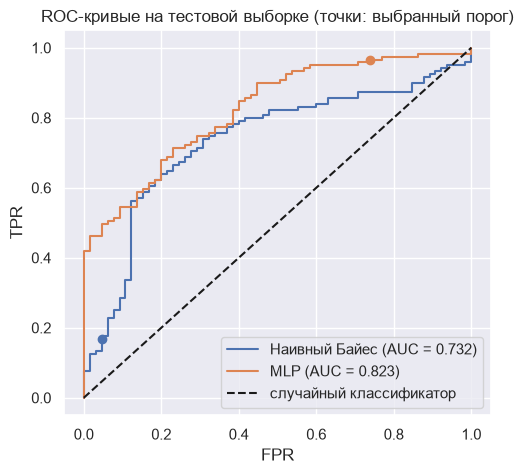

In [65]:
plt.figure(figsize=(5.5, 5))
aucs = {}
for name, model in models.items():
    scores = model.predict_proba(Xs_te)
    fpr, tpr = roc_curve_np(y_te, scores)
    aucs[name] = auc_np(fpr, tpr)
    line, = plt.plot(fpr, tpr, label=f"{name} (AUC = {aucs[name]:.3f})")
    pred = scores >= thresholds[name]
    plt.scatter(pred[y_te == 0].mean(), pred[y_te == 1].mean(), color=line.get_color(), zorder=3)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривые на тестовой выборке (точки: выбранный порог)")
plt.legend()
plt.show()

**Анализ ROC:** MLP обычно имеет более высокий AUC, чем Наивный Байес, что согласуется с её более высоким F1-score и recall на тестовой выборке. Поэтому MLP лучше ранжирует объекты по вероятности успеха независимо от конкретного порога.

Выбранный порог MLP находится на кривой в точке с относительно низким FPR и высоким TPR, поскольку порог 0.24 переводит почти 97% положительных объектов в положительный класс. Порог Наивного Байеса находится близко к началу кривой и дает низкий recall.

AUC удобнее accuracy при дисбалансе классов, поскольку оценивает качество ранжирования всех порогов и не зависит от одной фиксированной границы. Однако AUC не показывает оптимальный порог и не учитывает реальную стоимость FP и FN. Поэтому для практического решения порог дополнительно нужно выбирать по валидационной выборке с учетом цены ошибок.

### 8. Анализ ошибок (задание 4)

Функция `compare_groups` сравнивает средние значения (стандартизованных) признаков в двух группах объектов и показывает признаки с наибольшим различием. Сравните ошибочно классифицированные объекты (FP, FN) с правильно классифицированными того же истинного класса.

In [42]:
def compare_groups(Xs, names, mask_a, mask_b, label_a="A", label_b="B", top=8):
    diff = Xs[mask_a].mean(axis=0) - Xs[mask_b].mean(axis=0)
    order = np.argsort(-np.abs(diff))[:top][::-1]
    plt.barh([names[i] for i in order], diff[order])
    plt.title(f"Разница средних: {label_a} − {label_b}")
    plt.show()

Количество объектов:
FP: 3 FN: 99 TP: 20 TN: 62


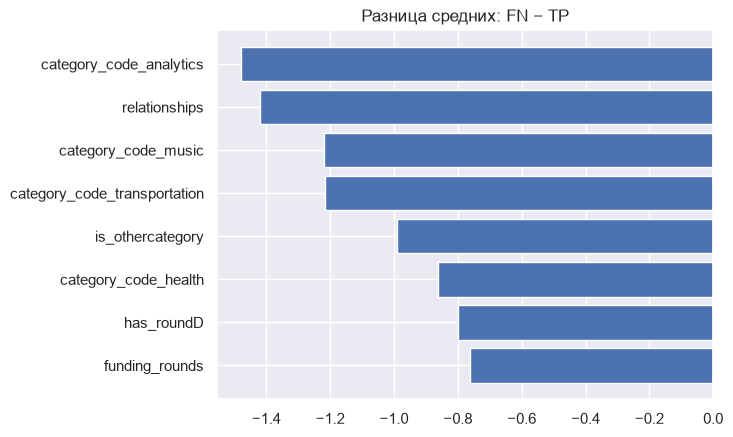

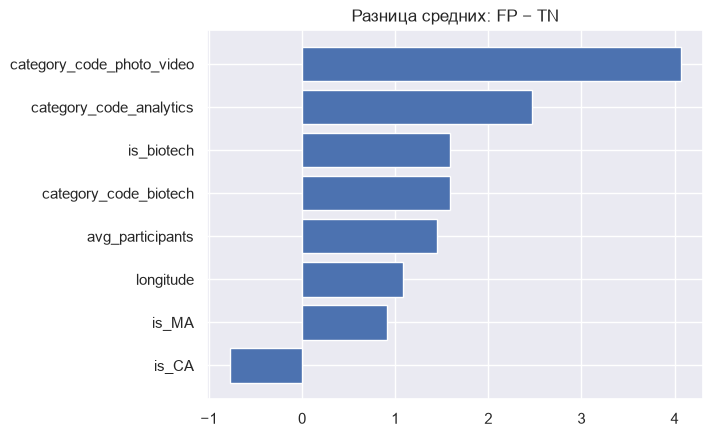

In [43]:
model_main = models[main_name]
y_hat = model_main.predict(Xs_te, thresholds[main_name])

fp = (y_te == 0) & (y_hat == 1)
fn = (y_te == 1) & (y_hat == 0)
tp = (y_te == 1) & (y_hat == 1)
tn = (y_te == 0) & (y_hat == 0)

print("Количество объектов:")
print("FP:", fp.sum(), "FN:", fn.sum(), "TP:", tp.sum(), "TN:", tn.sum())

compare_groups(Xs_te, feature_names, fn, tp, "FN", "TP")
compare_groups(Xs_te, feature_names, fp, tn, "FP", "TN")

**Анализ ошибок:** Полученные маски позволяют отделить ложные срабатывания (FP) от пропущенных успешных стартапов (FN) и сравнить их со всеми правильно классифицированными объектами соответствующего истинного класса. Стандартизованные признаки показывают, по каким характеристикам ошибочные объекты ближе к противоположному классу.

Вероятные причины ошибок: пограничные значения вероятности у объектов с противоречивыми признаками, выбросы в возрастных или финансовых признаках, а также неоднозначность категорий стартапов. Наивный байес может ошибаться сильнее в силу предположения о независимости признаков: коррелированные признаки и редкие категории искажают совместную плотность и «сдвигают» решение. Для итогового вывода следует обратить внимание на признаки с наибольшей разностью средних на двух графиках и проверить, не является ли разница следствием редкой категории или выброса.

### 9. Улучшение результатов (задание 4)

Попробуйте улучшить качество. Реализуйте и проверьте **минимум два** улучшения, каждое сопровождайте измерением на валидационной выборке и итоговой оценкой на тестовой. Идеи:

- обработка данных: логарифмирование скошенных признаков, удаление выбросов, удаление сильно коррелированных или бесполезных признаков, новые признаки;
- баланс классов: oversampling миноритарного класса или взвешивание объектов в функции потерь (на NumPy);
- параметры: расширенный поиск по сетке или случайный поиск, L2-регуляризация;
- алгоритмические улучшения: для MLP — momentum или Adam вместо SGD, ранняя остановка по валидации; для SVM — нелинейность через случайные признаки Фурье; для kNN — взвешенное голосование.

Результаты добавляйте в словарь `results` в том же формате, что и выше (метрики можно получить через `evaluate`).

In [ ]:

замена var_smoothing c 1e-9  на 1e-4
accuracy вырос до 0.4891
f1 вырос до 0.3974




NameError: name 'Xs_tr_new' is not defined

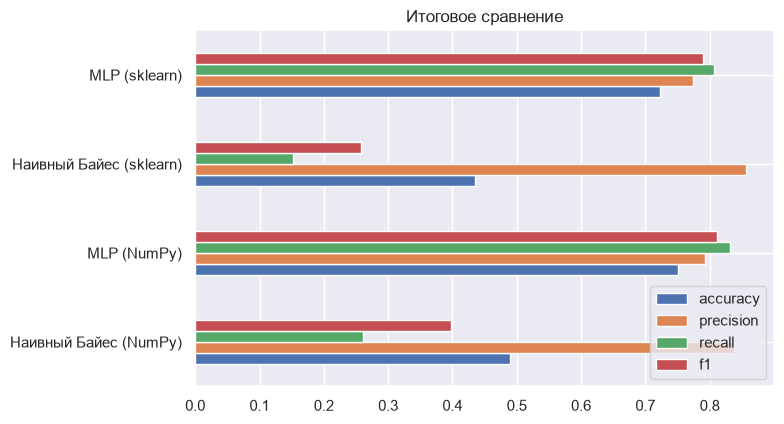

,accuracy,precision,recall,f1,fit_s,predict_s
Наивный Байес (NumPy),0.4891,0.8378,0.2605,0.3974,0.0012,0.0006
MLP (NumPy),0.7500,0.7920,0.8319,0.8115,0.0625,0.0006
Наивный Байес (sklearn),0.4348,0.8571,0.1513,0.2571,0.0026,0.0015
MLP (sklearn),0.7228,0.7742,0.8067,0.7901,0.5121,0.0006


In [75]:
final = pd.DataFrame(results).T.round(4)
final[["accuracy", "precision", "recall", "f1"]].plot.barh(figsize=(8, 0.6 * len(final) + 2))
plt.title("Итоговое сравнение")
plt.tight_layout()
plt.show()
final

### 10. Критерии приёма работы

Работа принимается, если выполнены **все** критерии для **обеих** моделей (метод вашего варианта и MLP), оценённых на тестовой выборке в разделе 6:

1. **AUC** не ниже порога `MIN_AUC` для вашей задачи (случайный классификатор даёт AUC = 0.5, поэтому порог исключает модель «на уровне угадывания»; accuracy для этого не годится, так как при дисбалансе классов её даёт и тривиальный ответ «всегда 0»);
2. **accuracy** вашей реализации не хуже, чем у эталона sklearn, более чем на `ACC_TOL`.

Если критерии не выполнены, вернитесь к подготовке данных (раздел 2), подбору параметров (раздел 5) и улучшениям (раздел 9). Эту ячейку менять не нужно.

In [73]:
checks = []
for name in models:
    auc_np_value = aucs[name]
    acc_np = results[f"{name} (NumPy)"]["accuracy"]
    acc_sk = results[f"{name} (sklearn)"]["accuracy"]
    checks.append((f"{name}: AUC ≥ {MIN_AUC[TASK]}", auc_np_value >= MIN_AUC[TASK], f"{auc_np_value:.3f}"))
    checks.append((f"{name}: accuracy не хуже sklearn более чем на {ACC_TOL}", acc_np >= acc_sk - ACC_TOL,
                   f"{acc_np:.3f} (sklearn {acc_sk:.3f})"))

table = pd.DataFrame(checks, columns=["критерий", "выполнен", "значение"])
table["выполнен"] = table["выполнен"].map({True: "да", False: "НЕТ"})
print(table.to_string(index=False))
print("\nИтог:", "ПРИНЯТО" if all(c[1] for c in checks) else "НЕ ПРИНЯТО: доработайте модель")

                                                 критерий выполнен              значение
                                 Наивный Байес: AUC ≥ 0.7       да                 0.732
Наивный Байес: accuracy не хуже sklearn более чем на 0.07       да 0.489 (sklearn 0.435)
                                           MLP: AUC ≥ 0.7       да                 0.823
          MLP: accuracy не хуже sklearn более чем на 0.07       да 0.750 (sklearn 0.723)

Итог: ПРИНЯТО


### 11. Итоговые выводы

1. Какая модель оказалась лучшей на вашей задаче и почему? Насколько ваша реализация на NumPy отличается от sklearn по качеству и по времени?
2. Какие гиперпараметры оказались самыми важными? Что происходит при их крайних значениях?
3. Какие улучшения дали эффект, а какие нет? Как вы это объясняете?
4. Какие ограничения у вашей реализации (масштабируемость, память, сходимость)? Что бы вы сделали на полном датасете?